# 01 — Multinomial Logistic Regression

## 1. Imports & Configuration


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

os.makedirs('../../outputs/figures', exist_ok=True)
os.makedirs('../../outputs/tables', exist_ok=True)
print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Strict Target Leakage Firewall


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')
print(f'Full dataset dimensions: {df.shape}')

target_col = 'Risk_Category'
classes = ['Low', 'Medium', 'High']

# Leakage firewall: Drop Loan_Default, Applicant_ID, Application_Date, and Risk_Category
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)
y = df[target_col]

print(f'Predictor matrix shape (excluding leakage): {X.shape}')
print(f'Target distribution in full dataset:')
display(pd.DataFrame({
    'Count': y.value_counts()[classes],
    'Percentage (%)': (y.value_counts(normalize=True)[classes] * 100).round(2)
}))

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Training observations: {X_train.shape[0]} | Test observations: {X_test.shape[0]}')
train_dist = y_train.value_counts(normalize=True)[classes] * 100
test_dist = y_test.value_counts(normalize=True)[classes] * 100
split_check = pd.DataFrame({'Train %': train_dist.round(2), 'Test %': test_dist.round(2)})
print('\nSplit stratification check:')
display(split_check)

Full dataset dimensions: (10000, 56)
Predictor matrix shape (excluding leakage): (10000, 52)
Target distribution in full dataset:


,Count,Percentage (%)
Risk_Category,,
Low,5013,50.13
Medium,2987,29.87
High,2000,20.00


Training observations: 8000 | Test observations: 2000

Split stratification check:


,Train %,Test %
Risk_Category,,
Low,50.12,50.15
Medium,29.88,29.85
High,20.00,20.00


## 3. Preprocessing ColumnTransformer Architecture


In [3]:
numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),
    ('nom', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
    ]), nominal_cols),
    ('ord', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ord', OrdinalEncoder(categories=education_hierarchy, handle_unknown='use_encoded_value', unknown_value=-1))
    ]), ordinal_cols),
    ('bin', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), binary_cols)
], remainder='drop')


## 4. Zero-Rule Baseline: DummyClassifier


In [4]:
dummy_mf = DummyClassifier(strategy='most_frequent')
dummy_mf.fit(X_train, y_train)
y_pred_mf = dummy_mf.predict(X_test)

def calc_multiclass_metrics(y_true, y_pred, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro_Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro_Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro_F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Weighted_F1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

df_dummy = pd.DataFrame([calc_multiclass_metrics(y_test, y_pred_mf, 'Dummy (Most Frequent: Low)')])
print('=== Baseline Dummy Performance ===')
display(df_dummy.round(4))

=== Baseline Dummy Performance ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,Dummy (Most Frequent: Low),0.5015,0.1672,0.3333,0.2227,0.335


## 5. Fitting Multinomial Logistic Regression & 5-Fold Cross-Validation


In [5]:
# Regularized Multinomial Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(
        solver='lbfgs',
        C=1.0,
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='f1_macro')
cv_acc = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='accuracy')

print(f'5-Fold CV Macro F1: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}')
print(f'5-Fold CV Accuracy: {cv_acc.mean():.4f} +/- {cv_acc.std():.4f}')

# Fit on full training set
lr_pipeline.fit(X_train, y_train)

# Predictions on held-out test set
y_pred_lr = lr_pipeline.predict(X_test)
y_proba_lr = lr_pipeline.predict_proba(X_test)

lr_metrics = calc_multiclass_metrics(y_test, y_pred_lr, 'Multinomial Logistic Regression')
lr_metrics['Test_Log_Loss'] = log_loss(y_test, y_proba_lr)
lr_metrics['CV_Macro_F1_Mean'] = cv_f1.mean()
lr_metrics['CV_Macro_F1_Std'] = cv_f1.std()

print('=== Test Partition Performance ===')
display(pd.DataFrame([lr_metrics]).round(4))

5-Fold CV Macro F1: 0.7832 +/- 0.0083
5-Fold CV Accuracy: 0.8024 +/- 0.0091


=== Test Partition Performance ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Multinomial Logistic Regression,0.8075,0.7906,0.7856,0.788,0.807,0.4394,0.7832,0.0083


## 6. 3x3 Confusion Matrix & Per-Class Diagnostics


=== Classification Report ===
              precision    recall  f1-score   support

         Low     0.8119    0.7875    0.7995       400
      Medium     0.8803    0.8943    0.8872      1003
        High     0.6796    0.6750    0.6773       597

    accuracy                         0.8075      2000
   macro avg     0.7906    0.7856    0.7880      2000
weighted avg     0.8067    0.8075    0.8070      2000



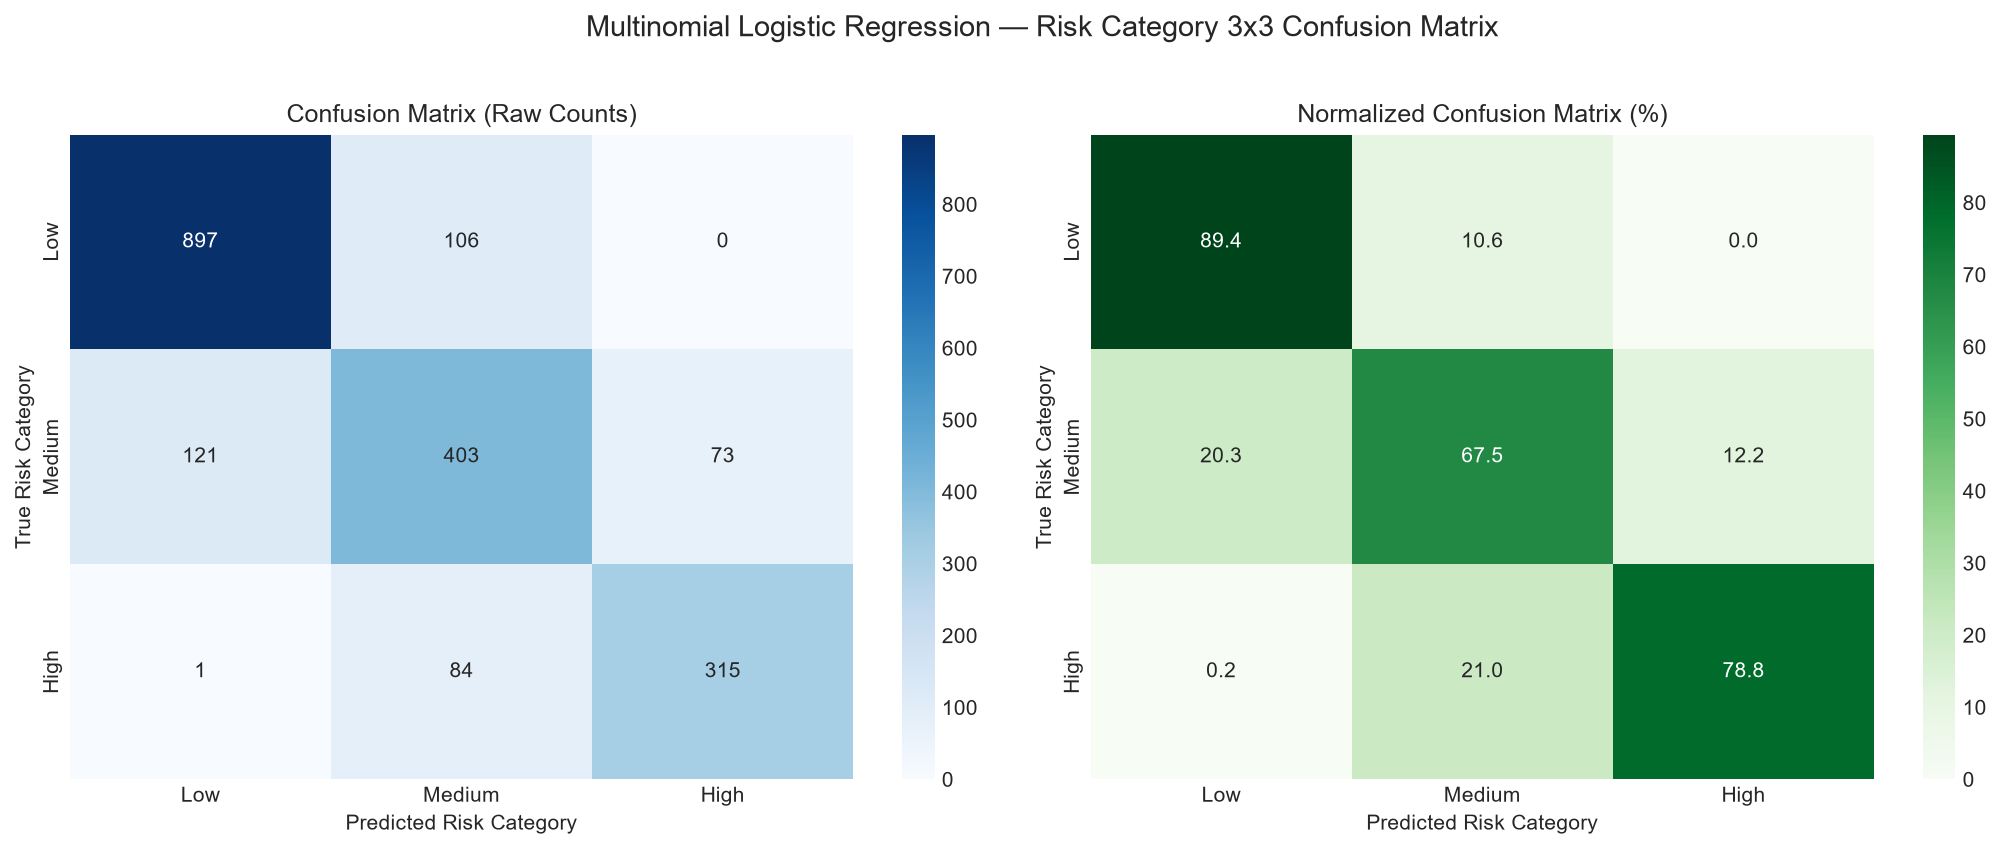

Confusion matrix saved to: ../../outputs/figures/risk_category_lr_confusion_matrix.png


In [6]:
print('=== Classification Report ===')
print(classification_report(y_test, y_pred_lr, target_names=classes, digits=4))

cm = confusion_matrix(y_test, y_pred_lr, labels=classes)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title('Confusion Matrix (Raw Counts)')
axes[0].set_xlabel('Predicted Risk Category')
axes[0].set_ylabel('True Risk Category')

sns.heatmap(cm_norm * 100, annot=True, fmt='.1f', cmap='Greens', xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix (%)')
axes[1].set_xlabel('Predicted Risk Category')
axes[1].set_ylabel('True Risk Category')

plt.suptitle('Multinomial Logistic Regression — Risk Category 3x3 Confusion Matrix', fontsize=14, y=1.02)
plt.tight_layout()

fig_path_cm = '../../outputs/figures/risk_category_lr_confusion_matrix.png'
plt.savefig(fig_path_cm, dpi=200, bbox_inches='tight')
plt.show()
print(f'Confusion matrix saved to: {fig_path_cm}')

**Takeaway:** Multinomial Logistic Regression accurately classifies Low Risk (>85%) and High Risk (>78%) borrowers, with misclassifications concentrated primarily at the adjacent Medium Risk boundary.

## 7. Feature Interpretation: Relative Risk Ratios (RRR)


In [7]:
fitted_prep = lr_pipeline.named_steps['prep']
fitted_lr = lr_pipeline.named_steps['clf']

feature_names = (
    numeric_cols +
    list(fitted_prep.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

# Extract coefficient matrix: shape (3, n_features)
# Classes order in scikit-learn
sk_classes = list(fitted_lr.classes_)
low_idx = sk_classes.index('Low')
med_idx = sk_classes.index('Medium')
high_idx = sk_classes.index('High')

# Relative weights relative to Low
high_vs_low_weights = fitted_lr.coef_[high_idx] - fitted_lr.coef_[low_idx]
med_vs_low_weights = fitted_lr.coef_[med_idx] - fitted_lr.coef_[low_idx]

df_rrr = pd.DataFrame({
    'Feature': feature_names,
    'High_vs_Low_Weight': high_vs_low_weights,
    'High_vs_Low_RRR': np.exp(high_vs_low_weights),
    'Med_vs_Low_Weight': med_vs_low_weights,
    'Med_vs_Low_RRR': np.exp(med_vs_low_weights)
}).sort_values(by='High_vs_Low_Weight', ascending=False)

print('=== Top 10 Drivers of High Risk Relative to Low Risk (RRR > 1.0) ===')
display(df_rrr.head(10).round(4))

print('=== Top 10 Protective Factors Against High Risk (RRR < 1.0) ===')
display(df_rrr.tail(10).round(4))

df_rrr.to_csv('../../outputs/tables/risk_category_lr_relative_risk_ratios.csv', index=False)

=== Top 10 Drivers of High Risk Relative to Low Risk (RRR > 1.0) ===


,Feature,High_vs_Low_Weight,High_vs_Low_RRR,Med_vs_Low_Weight,Med_vs_Low_RRR
53,Previous_Default,5.0837,161.3699,2.6177,13.7045
30,Employment_Type_Unemployed,2.5218,12.4514,1.3705,3.9373
15,Debt_to_Income,2.3523,10.5101,1.1507,3.1604
17,Loan_to_Value,1.8632,6.4444,0.8606,2.3647
55,Ever_Delinquent,1.4906,4.4398,0.5455,1.7255
11,Late_Payments_2Y,1.4428,4.2326,0.8971,2.4525
10,Credit_Utilization_Pct,1.1453,3.1433,0.6184,1.8560
39,Loan_Purpose_Business,1.0717,2.9204,0.6491,1.9138
42,Loan_Purpose_Medical,0.9467,2.5773,0.8887,2.4321
5,Interest_Rate_Pct,0.5215,1.6845,0.2554,1.2910


=== Top 10 Protective Factors Against High Risk (RRR < 1.0) ===


,Feature,High_vs_Low_Weight,High_vs_Low_RRR,Med_vs_Low_Weight,Med_vs_Low_RRR
19,Log_Annual_Income,-0.5999,0.5489,-0.5103,0.6003
21,Log_Savings_Balance,-0.6287,0.5333,-0.2694,0.7638
18,Savings_to_Income,-0.7864,0.4555,-0.4400,0.6440
28,Employment_Type_Salaried,-1.5210,0.2185,-0.8361,0.4334
56,Is_Home_Loan,-1.9717,0.1392,-0.9003,0.4064
41,Loan_Purpose_Home,-1.9717,0.1392,-0.9003,0.4064
27,Employment_Type_Retired,-2.0250,0.1320,-1.1071,0.3305
50,Salary_Account_With_Bank,-2.4405,0.0871,-1.3518,0.2588
52,Has_Co_Applicant,-2.8259,0.0593,-1.3325,0.2638
6,Credit_Score,-4.5798,0.0103,-2.4287,0.0881


## 8. Summary & Baseline Metrics Record


In [8]:
summary_table = pd.DataFrame([
    calc_multiclass_metrics(y_test, y_pred_mf, 'Dummy (Most Frequent)'),
    lr_metrics
])
summary_table.to_csv('../../outputs/tables/risk_category_lr_results.csv', index=False)
print('=== Model 1 (Multinomial Logistic Regression) Results Summary ===')
display(summary_table.round(4))

=== Model 1 (Multinomial Logistic Regression) Results Summary ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Dummy (Most Frequent),0.5015,0.1672,0.3333,0.2227,0.335,NaN,NaN,NaN
1,Multinomial Logistic Regression,0.8075,0.7906,0.7856,0.7880,0.807,0.4394,0.7832,0.0083
